1. VECTOR AND MATRIX OPERATIONS FOR DEEP LEARNING

Addition: [5 7 9]
Subtraction: [-3 -3 -3]
Dot Product: 32
Matrix Addition:
 [[ 6  8]
 [10 12]]
Matrix Multiplication:
 [[19 22]
 [43 50]]
Transpose:
 [[1 3]
 [2 4]]
Inverse:
 [[-2.   1. ]
 [ 1.5 -0.5]]


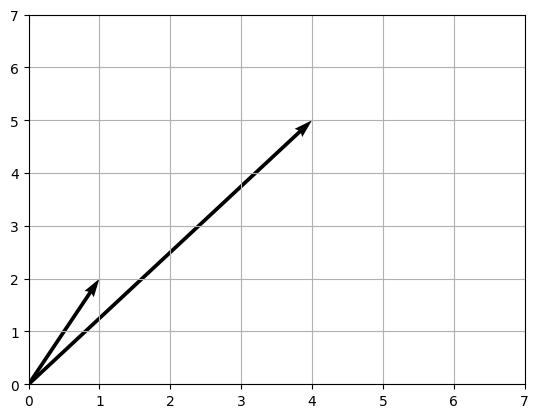

In [12]:
import numpy as np
import matplotlib.pyplot as plt

a=np.array([1,2,3]); b=np.array([4,5,6])
print("Addition:",a+b)
print("Subtraction:",a-b)
print("Dot Product:",np.dot(a,b))

A=np.array([[1,2],[3,4]]); B=np.array([[5,6],[7,8]])
print("Matrix Addition:\n",A+B)
print("Matrix Multiplication:\n",A@B)
print("Transpose:\n",A.T)
print("Inverse:\n",np.linalg.inv(A))

plt.quiver(0,0,a[0],a[1],angles='xy',scale_units='xy',scale=1)
plt.quiver(0,0,b[0],b[1],angles='xy',scale_units='xy',scale=1)
plt.xlim(0,7); plt.ylim(0,7); plt.grid(); plt.show()

2. COVARIANCE, EIGENVALUES AND EIGENVECTORS

Dataset:
   Height  Weight
0     150      50
1     155      54
2     160      58
3     165      63
4     170      68
5     175      72
6     180      78

Covariance Matrix:
[[116.66666667 108.33333333]
 [108.33333333 100.9047619 ]]

Eigenvalues:
[2.17405328e+02 1.66100396e-01]

Eigenvectors:
[[ 0.73230988 -0.68097154]
 [ 0.68097154  0.73230988]]


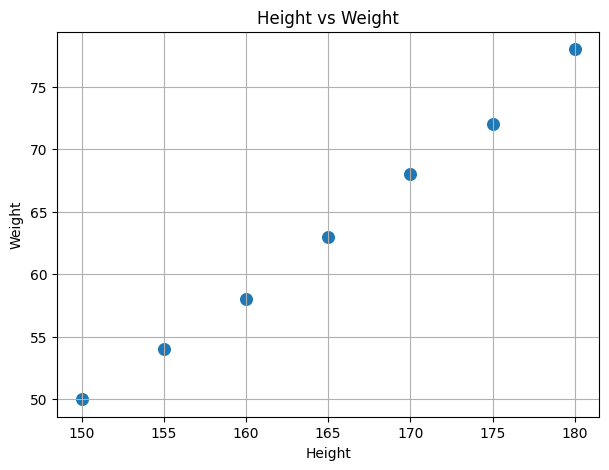

In [8]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Create dataset
data = {
    "Height": [150, 155, 160, 165, 170, 175, 180],
    "Weight": [50, 54, 58, 63, 68, 72, 78]
}

df = pd.DataFrame(data)

print("Dataset:")
print(df)

# Calculate covariance matrix
cov_matrix = np.cov(df["Height"], df["Weight"])

print("\nCovariance Matrix:")
print(cov_matrix)

# Calculate eigenvalues and eigenvectors
eigenvalues, eigenvectors = np.linalg.eig(cov_matrix)

print("\nEigenvalues:")
print(eigenvalues)

print("\nEigenvectors:")
print(eigenvectors)

# Visualization
plt.figure(figsize=(7, 5))

plt.scatter(df["Height"], df["Weight"], s=70)

plt.xlabel("Height")
plt.ylabel("Weight")
plt.title("Height vs Weight")
plt.grid()

plt.show()

3. PROBABILITY DISTRIBUTIONS AND BAYES' THEOREM

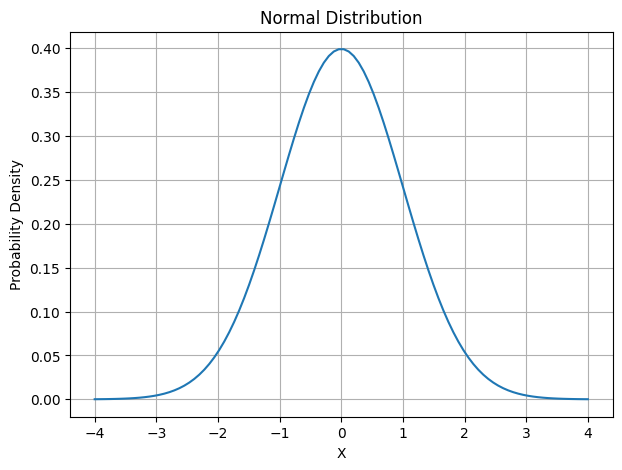

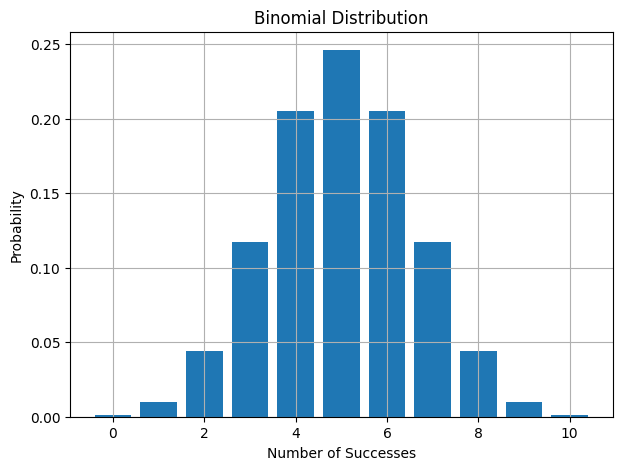

P(Disease): 0.01
P(Positive Test): 0.059000000000000004
P(Disease | Positive Test): 0.16101694915254236


In [9]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm, binom

# -------------------------------
# NORMAL DISTRIBUTION
# -------------------------------

x = np.linspace(-4, 4, 100)

normal_pdf = norm.pdf(x, loc=0, scale=1)

plt.figure(figsize=(7, 5))
plt.plot(x, normal_pdf)
plt.xlabel("X")
plt.ylabel("Probability Density")
plt.title("Normal Distribution")
plt.grid()
plt.show()

# -------------------------------
# BINOMIAL DISTRIBUTION
# -------------------------------

n = 10
p = 0.5

x_binomial = np.arange(0, n + 1)
binomial_prob = binom.pmf(x_binomial, n, p)

plt.figure(figsize=(7, 5))
plt.bar(x_binomial, binomial_prob)
plt.xlabel("Number of Successes")
plt.ylabel("Probability")
plt.title("Binomial Distribution")
plt.grid()
plt.show()

# -------------------------------
# BAYES' THEOREM
# -------------------------------

# Probability of disease
P_D = 0.01

# Probability of positive test given disease
P_Pos_D = 0.95

# Probability of positive test given no disease
P_Pos_notD = 0.05

# Probability of no disease
P_notD = 1 - P_D

# Total probability of positive test
P_Pos = (P_Pos_D * P_D) + (P_Pos_notD * P_notD)

# Bayes theorem
P_D_Pos = (P_Pos_D * P_D) / P_Pos

print("P(Disease):", P_D)
print("P(Positive Test):", P_Pos)
print("P(Disease | Positive Test):", P_D_Pos)

4. ENTROPY, CROSS-ENTROPY AND KL DIVERGENCE

Distribution P: [0.7 0.2 0.1]
Distribution Q: [0.6 0.3 0.1]

Entropy of P: 1.1567796494470395
Cross-Entropy: 1.1954618442383218
KL Divergence: 0.03868219479128224


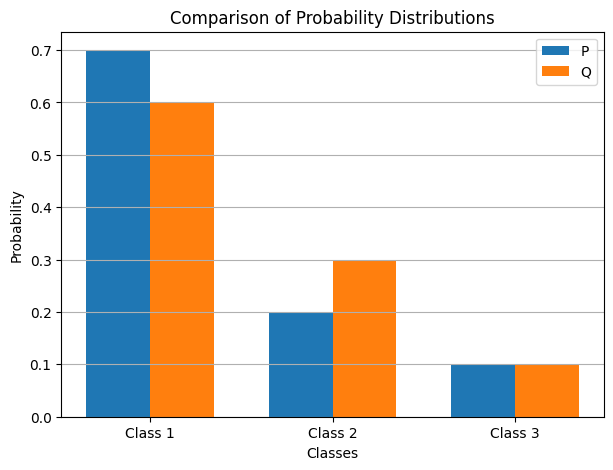

In [10]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import entropy

# Probability distributions
P = np.array([0.7, 0.2, 0.1])
Q = np.array([0.6, 0.3, 0.1])

# Entropy of P
H_P = entropy(P, base=2)

# Cross-entropy
cross_entropy = -np.sum(P * np.log2(Q))

# KL Divergence
KL_divergence = entropy(P, Q, base=2)

print("Distribution P:", P)
print("Distribution Q:", Q)

print("\nEntropy of P:", H_P)
print("Cross-Entropy:", cross_entropy)
print("KL Divergence:", KL_divergence)

# Visualization
labels = ["Class 1", "Class 2", "Class 3"]

x = np.arange(len(labels))
width = 0.35

plt.figure(figsize=(7, 5))

plt.bar(x - width/2, P, width, label="P")
plt.bar(x + width/2, Q, width, label="Q")

plt.xlabel("Classes")
plt.ylabel("Probability")
plt.title("Comparison of Probability Distributions")
plt.xticks(x, labels)
plt.legend()
plt.grid(axis='y')

plt.show()

5. BIAS-VARIANCE, OVERFITTING AND UNDERFITTING

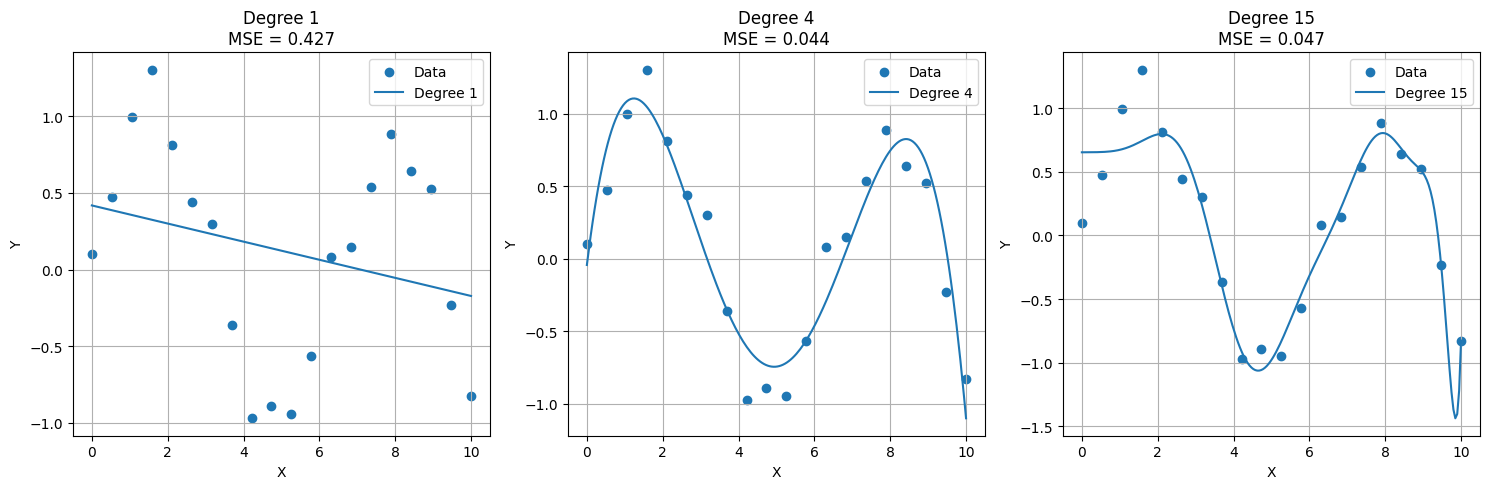

In [11]:
import numpy as np
import matplotlib.pyplot as plt

from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import make_pipeline
from sklearn.metrics import mean_squared_error

# Generate dataset
np.random.seed(42)

X = np.linspace(0, 10, 20)
y = np.sin(X) + np.random.normal(0, 0.2, 20)

X = X.reshape(-1, 1)

# Create smooth X values for plotting
X_plot = np.linspace(0, 10, 200).reshape(-1, 1)

# Polynomial degrees
degrees = [1, 4, 15]

plt.figure(figsize=(15, 5))

for i, degree in enumerate(degrees):

    # Create polynomial regression model
    model = make_pipeline(
        PolynomialFeatures(degree),
        LinearRegression()
    )

    # Train model
    model.fit(X, y)

    # Prediction
    y_pred = model.predict(X_plot)

    # Training prediction
    y_train_pred = model.predict(X)

    # Mean Squared Error
    mse = mean_squared_error(y, y_train_pred)

    # Plot
    plt.subplot(1, 3, i + 1)

    plt.scatter(X, y, label="Data")
    plt.plot(X_plot, y_pred, label=f"Degree {degree}")

    plt.xlabel("X")
    plt.ylabel("Y")
    plt.title(f"Degree {degree}\nMSE = {mse:.3f}")
    plt.legend()
    plt.grid()

plt.tight_layout()
plt.show()